In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 

In [2]:
df = pd.read_csv("smartcart_customers.csv")

In [3]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,172,88,88,3,8,10,4,7,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,2,1,6,2,1,1,2,5,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,111,21,42,1,8,2,10,4,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,10,3,5,2,2,0,4,6,0,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,46,27,15,5,5,3,6,5,0,0


In [4]:
df.shape

(2240, 22)

In [5]:
df.isnull().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
Complain                0
Response                0
dtype: int64

# Data Preprocessing 

## 1) handle missing values

In [6]:
df["Income"] = df["Income"].fillna(df["Income"].median())

In [7]:
df.isnull().sum()

ID                     0
Year_Birth             0
Education              0
Marital_Status         0
Income                 0
Kidhome                0
Teenhome               0
Dt_Customer            0
Recency                0
MntWines               0
MntFruits              0
MntMeatProducts        0
MntFishProducts        0
MntSweetProducts       0
MntGoldProds           0
NumDealsPurchases      0
NumWebPurchases        0
NumCatalogPurchases    0
NumStorePurchases      0
NumWebVisitsMonth      0
Complain               0
Response               0
dtype: int64

## 2) feature engineering

In [8]:
# age 

df["Age"]  =  2026-df["Year_Birth"] 

In [9]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,88,88,3,8,10,4,7,0,1,69
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,1,6,2,1,1,2,5,0,0,72
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,21,42,1,8,2,10,4,0,0,61
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,3,5,2,2,0,4,6,0,0,42
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,27,15,5,5,3,6,5,0,0,45


In [10]:
# customer tenure days - we will convert "Dt_Customer" into tenure days , by choosing the max date as the reference date and using that finding the tenure days for other customers by subtracting their date from the refrence date 

df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"],dayfirst=True) # converting from string format to proper datetime format, dayfirst = True tells pandas to interpret dates as DD-MM-YYYY rather than its default format which is MM-DD-YYYY

reference_date = df["Dt_Customer"].max()

df["customer_tenure_days"] = (reference_date - df["Dt_Customer"]).dt.days



In [11]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,customer_tenure_days
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,88,3,8,10,4,7,0,1,69,663
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,6,2,1,1,2,5,0,0,72,113
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,42,1,8,2,10,4,0,0,61,312
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,5,2,2,0,4,6,0,0,42,139
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,15,5,5,3,6,5,0,0,45,161


In [12]:
# spending

df["total_spending"] = df["MntWines"]+df["MntFruits"]+df["MntMeatProducts"]+df["MntFishProducts"]+df["MntSweetProducts"]+df["MntGoldProds"]


In [13]:
# children

df["total_childern"] = df["Kidhome"]+df["Teenhome"]

In [14]:
# education 

df["Education"].value_counts()

# undergraduate, graduate, postgraduate

df["Education"] = df["Education"].replace({
    "Basic": "undergraduate",
    "2n Cycle": "undergraduate",
    "Graduation": "graduate",
    "Master": "postgraduate",
    "PhD": "postgraduate"
})


In [15]:
df["Education"].value_counts()

Education
graduate         1127
postgraduate      856
undergraduate     257
Name: count, dtype: int64

In [16]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,customer_tenure_days,total_spending,total_childern
0,5524,1957,graduate,Single,58138.0,0,0,2012-09-04,58,635,...,8,10,4,7,0,1,69,663,1617,0
1,2174,1954,graduate,Single,46344.0,1,1,2014-03-08,38,11,...,1,1,2,5,0,0,72,113,27,2
2,4141,1965,graduate,Together,71613.0,0,0,2013-08-21,26,426,...,8,2,10,4,0,0,61,312,776,0
3,6182,1984,graduate,Together,26646.0,1,0,2014-02-10,26,11,...,2,0,4,6,0,0,42,139,53,1
4,5324,1981,postgraduate,Married,58293.0,1,0,2014-01-19,94,173,...,5,3,6,5,0,0,45,161,422,1


In [17]:
# marital status

df["Marital_Status"].value_counts()

df["living_with"] = df["Marital_Status"].replace({
    "Married": "partner",
    "Together": "partner",
    "Single": "Alone",
    "Divorced": "Alone",
    "Widow": "Alone",
    "Absurd": "Alone",
    "YOLO": "Alone"
})

In [18]:
df["living_with"].value_counts()

living_with
partner    1444
Alone       796
Name: count, dtype: int64

In [19]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'Complain', 'Response', 'Age', 'customer_tenure_days', 'total_spending',
       'total_childern', 'living_with'],
      dtype='object')

## 3) drop columns

In [20]:
cols = ["ID","Year_Birth","Marital_Status","Kidhome","Teenhome","Dt_Customer"]
spending_cols = ["MntWines","MntFruits","MntMeatProducts","MntFishProducts","MntSweetProducts","MntGoldProds"]

cols_to_drop = cols+spending_cols

df_cleaned = df.drop(columns = cols_to_drop)

In [21]:
df_cleaned

,Education,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,customer_tenure_days,total_spending,total_childern,living_with
0,graduate,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,Alone
1,graduate,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,Alone
2,graduate,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,partner
3,graduate,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,partner
4,postgraduate,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,partner
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,graduate,61223.0,46,2,9,3,4,5,0,0,59,381,1341,1,partner
2236,postgraduate,64014.0,56,7,8,2,5,7,0,0,80,19,444,3,partner
2237,graduate,56981.0,91,1,2,3,13,6,0,0,45,155,1241,0,Alone
2238,postgraduate,69245.0,8,2,6,5,10,3,0,0,70,156,843,1,partner


## 4) outliers

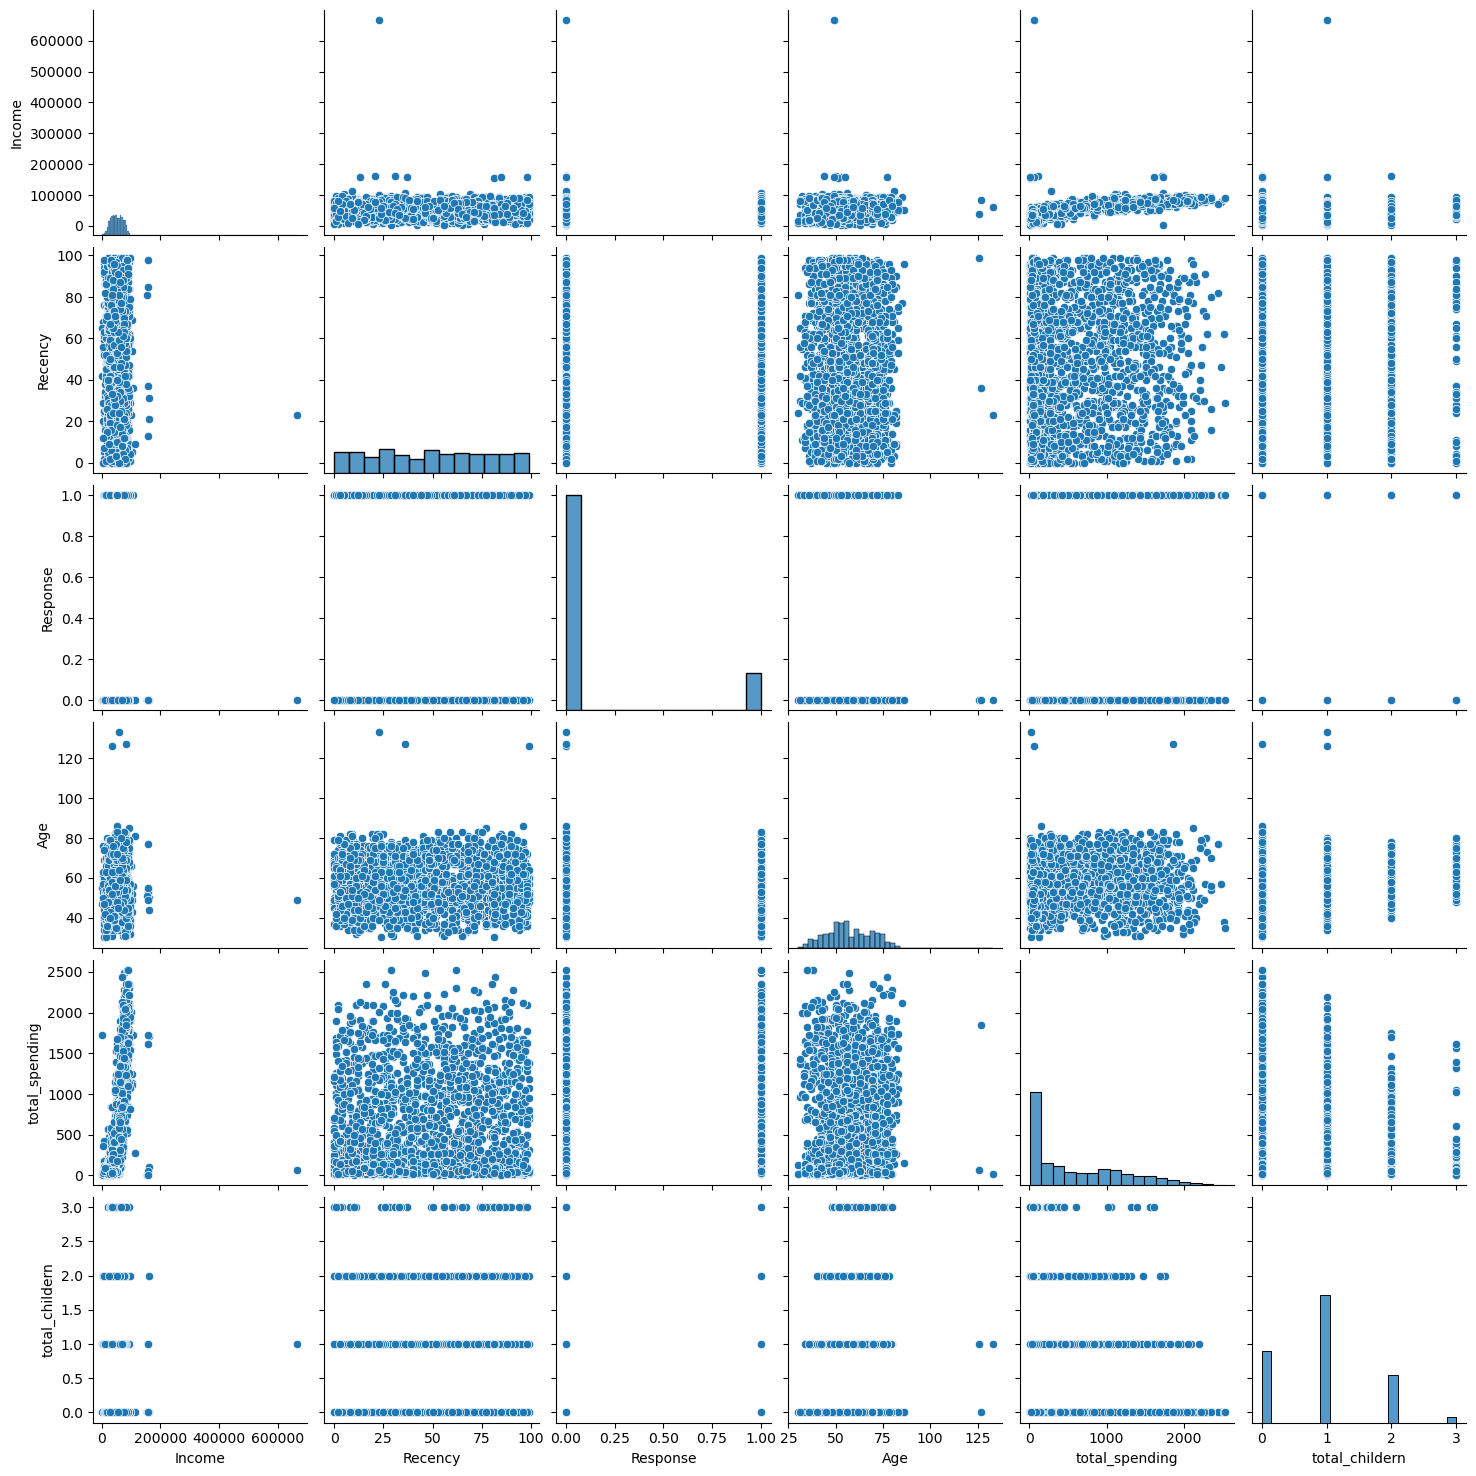

In [22]:
cols = ["Income","Recency","Response","Age","total_spending","total_childern"]

# relative plots of some features - pair plots
sns.pairplot(df_cleaned[cols])

# outliers in  - income , age

In [23]:
# remove outliers

print("data size with outliers", len(df_cleaned))

df_cleaned = df_cleaned[(df_cleaned["Age"]<90)]
df_cleaned = df_cleaned[(df_cleaned["Income"]<600_000)]

print("data size without outliers", len(df_cleaned))

data size with outliers 2240
data size without outliers 2236


## 5) heatmaps

In [24]:
corr = df_cleaned.corr(numeric_only=True)

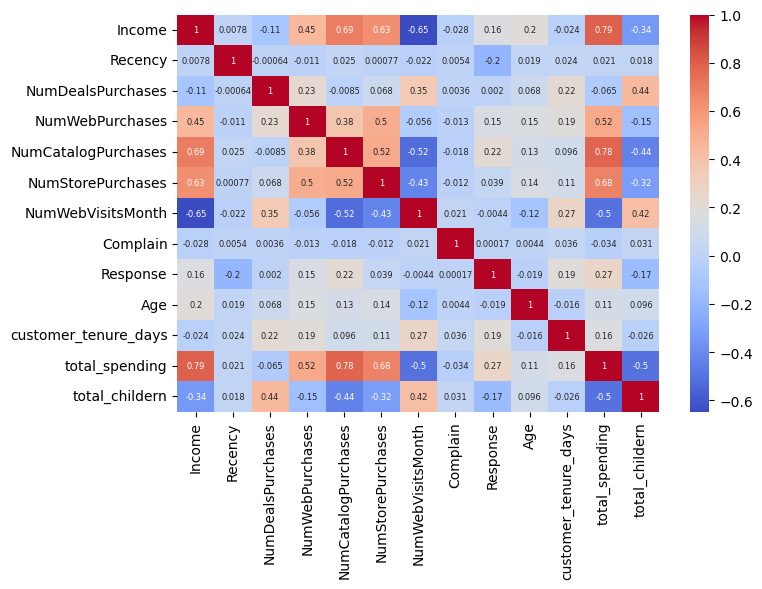

In [25]:
plt.figure(figsize=(8,6))

sns.heatmap(
    corr,
    annot=True,
    annot_kws={"size":6},
    cmap="coolwarm"
)

plt.tight_layout()

# high correlation between features doesn't mean they are important features
# for Clustering , feature importance is usually evaluated through PCA, silhoute score and buisness interpretability rather than correlation alone
# strong correlations are more useful for spotting redundant features 

In [26]:
# 0.79 - income / total-spending
# 0.69 - income / catalog products
# 0.63 - income / store purchase
# -0.65 - income / no of web visits
# 0.78 - spending / catalog purchases
# 0.68 - spending / store

In [27]:
df_cleaned.head()

,Education,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,customer_tenure_days,total_spending,total_childern,living_with
0,graduate,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,Alone
1,graduate,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,Alone
2,graduate,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,partner
3,graduate,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,partner
4,postgraduate,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,partner


## 6) Encoding

In [28]:
from sklearn.preprocessing import OneHotEncoder

In [29]:
ohe = OneHotEncoder()

cat_cols = ["Education","living_with"]

enc_cols = ohe.fit_transform(df_cleaned[cat_cols])

In [30]:
enc_cols

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 4472 stored elements and shape (2236, 5)>

In [31]:
enc_df = pd.DataFrame(enc_cols.toarray(),columns=ohe.get_feature_names_out(cat_cols),index=df_cleaned.index)

In [32]:
enc_df.head()

,Education_graduate,Education_postgraduate,Education_undergraduate,living_with_Alone,living_with_partner
0,1.0,0.0,0.0,1.0,0.0
1,1.0,0.0,0.0,1.0,0.0
2,1.0,0.0,0.0,0.0,1.0
3,1.0,0.0,0.0,0.0,1.0
4,0.0,1.0,0.0,0.0,1.0


In [33]:
df_encoded = pd.concat([df_cleaned.drop(columns = cat_cols),enc_df],axis=1)

In [34]:
df_encoded.shape

(2236, 18)

In [35]:
df_encoded.head()

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,customer_tenure_days,total_spending,total_childern,Education_graduate,Education_postgraduate,Education_undergraduate,living_with_Alone,living_with_partner
0,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,1.0,0.0,0.0,1.0,0.0
1,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,1.0,0.0,0.0,1.0,0.0
2,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,1.0,0.0,0.0,0.0,1.0
3,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,1.0,0.0,0.0,0.0,1.0
4,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,0.0,1.0,0.0,0.0,1.0


## 7) Scaling 

In [36]:
from sklearn.preprocessing import StandardScaler

In [37]:
X = df_encoded

In [38]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

## 8) Visualise

In [39]:
# 2D
from sklearn.decomposition import PCA

In [40]:
pca = PCA(n_components = 2)

X_pca = pca.fit_transform(X_scaled)

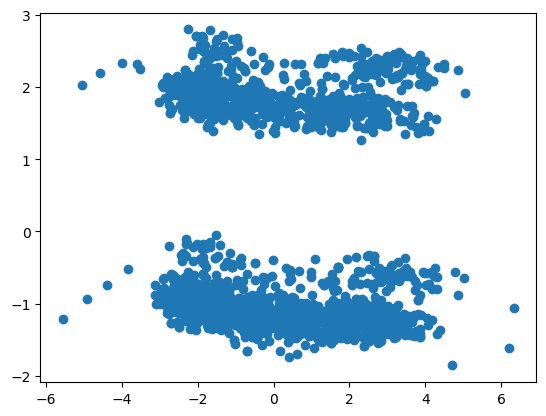

In [41]:
# plot 

plt.scatter(
    X_pca[:,0],
    X_pca[:,1]
)

In [42]:
pca.explained_variance_ratio_ 

# so x-axis captures - 23% variance & y-axis captures - 11% variance , so totally it captures only 34% variance of the data
# so most of the info is being lost
# so to capture more info of the data , we can increase the number of dimensions(features)


array([0.23163158, 0.11385454])

In [43]:
# 3D

pca = PCA(n_components = 3)

X_pca = pca.fit_transform(X_scaled)

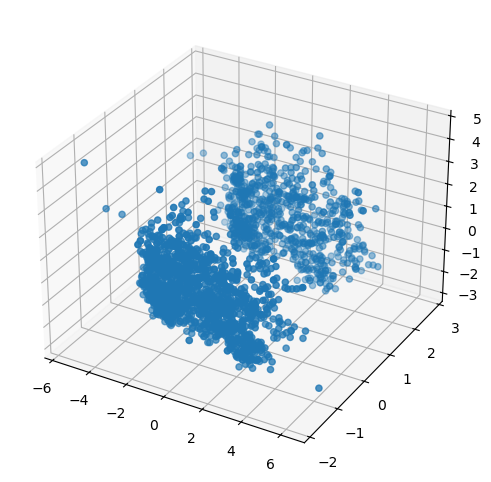

In [44]:
# plot 

fig = plt.figure(figsize=(8,6))

ax = fig.add_subplot(111,projection="3d")

ax.scatter(
    X_pca[:,0],
    X_pca[:,1],
    X_pca[:,2]
    
)

## 9) K value

### 1) Elbow method

In [45]:
from sklearn.cluster import KMeans
from kneed import KneeLocator

wcss = []
for k in range(1,11):
    kmeans = KMeans(n_clusters=k)
    random_state = 42
    kmeans.fit_predict(X_pca)
    wcss.append(kmeans.inertia_)




In [46]:
knee = KneeLocator(range(1,11),wcss,curve="convex",direction="decreasing")

In [47]:
optimal_k = knee.elbow

In [48]:
optimal_k # k = 4

np.int64(4)

<Axes: >

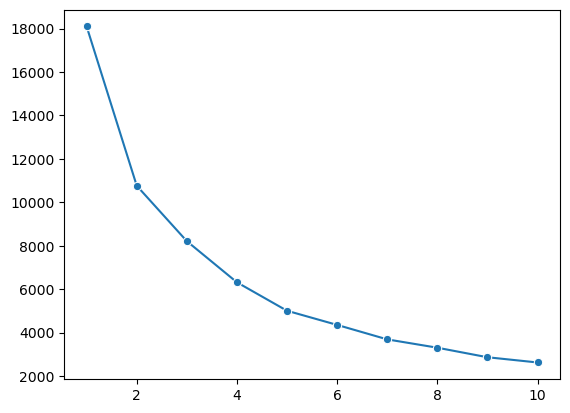

In [49]:
sns.lineplot(x = range(1,11),y = wcss,marker="o")

### 2) silhoute score

In [56]:
from sklearn.metrics import silhouette_score

scores = []

for k in range(2,11):
    kmeans = KMeans(n_clusters=k,random_state = 42)
    labels = kmeans.fit_predict(X_pca)
    score = silhouette_score(X_pca,labels)
    scores.append(score)

<Axes: >

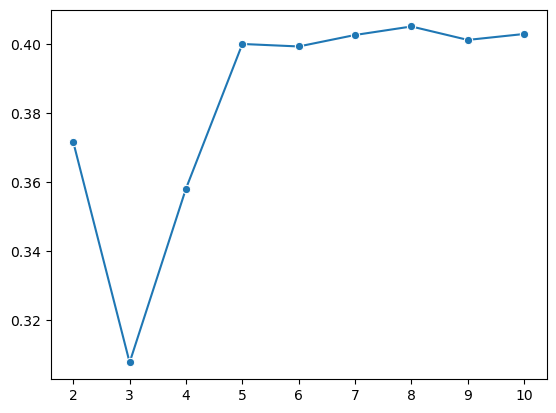

In [57]:
sns.lineplot(x = range(2,11),y = scores,marker="o")

Text(0, 0.5, 'ss')

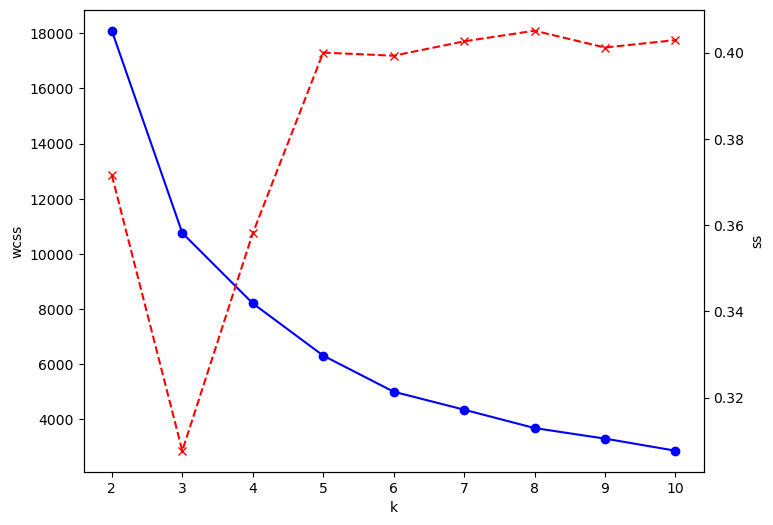

In [62]:
## that k value is selected which is near to the intersection of both the curves both wcss and silhouette score

## combined plot
k_range = range(2,11)
fig,ax1 = plt.subplots(figsize=(8,6))

ax1.plot(k_range,wcss[:len(k_range)],marker="o",color="blue")
ax1.set_xlabel("k")
ax1.set_ylabel("wcss")

ax2 = ax1.twinx() ## ax2 have same x-axis as ax1
ax2.plot(k_range,scores[:len(k_range)],marker="x",color="red",linestyle="--")
ax2.set_ylabel("ss")

In [63]:
# so they intersect around k = 4 , so optimal k value is 4 

## 10) clustering

In [64]:
# k_means

kmeans = KMeans(n_clusters=4,random_state=42)
labels = kmeans.fit_predict(X_pca)

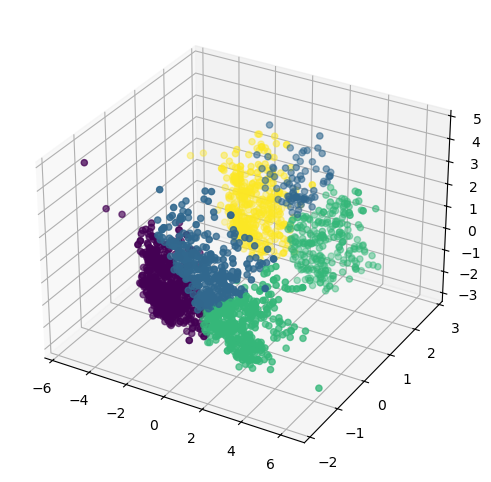

In [69]:
fig = plt.figure(figsize=(8,6))

ax = fig.add_subplot(111,projection="3d")

ax.scatter(
    X_pca[:,0],
    X_pca[:,1],
    X_pca[:,2],
    c = labels
    
)

In [70]:
# agglomerative clustering 
from sklearn.cluster import AgglomerativeClustering


In [71]:
agg_clf = AgglomerativeClustering(n_clusters=4,linkage="ward")
labels_agg = agg_clf.fit_predict(X_pca)

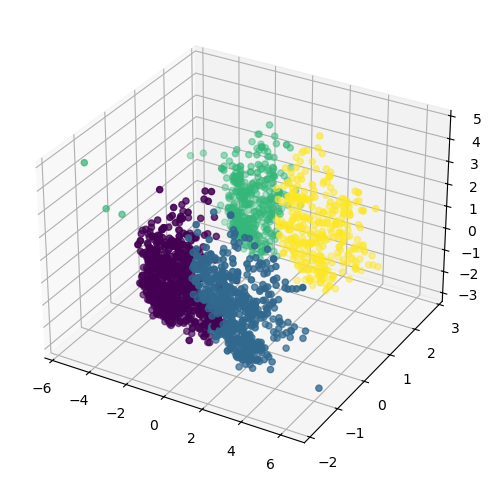

In [72]:
fig = plt.figure(figsize=(8,6))

ax = fig.add_subplot(111,projection="3d")

ax.scatter(
    X_pca[:,0],
    X_pca[:,1],
    X_pca[:,2],
    c = labels_agg
    
)

## 11) Characterization of clusters

In [91]:
df_cleaned.head()

,Education,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,customer_tenure_days,total_spending,total_childern,living_with,labels,clusters
0,graduate,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,Alone,3,3
1,graduate,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,Alone,2,2
2,graduate,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,partner,1,1
3,graduate,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,partner,0,0
4,postgraduate,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,partner,0,0


In [87]:
df_cleaned.drop("labels",axis=1)

,Education,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,customer_tenure_days,total_spending,total_childern,living_with,clusters
0,graduate,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,Alone,3
1,graduate,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,Alone,2
2,graduate,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,partner,1
3,graduate,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,partner,0
4,postgraduate,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,partner,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,graduate,61223.0,46,2,9,3,4,5,0,0,59,381,1341,1,partner,0
2236,postgraduate,64014.0,56,7,8,2,5,7,0,0,80,19,444,3,partner,0
2237,graduate,56981.0,91,1,2,3,13,6,0,0,45,155,1241,0,Alone,3
2238,postgraduate,69245.0,8,2,6,5,10,3,0,0,70,156,843,1,partner,1


In [92]:
df_cleaned.head()


,Education,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,customer_tenure_days,total_spending,total_childern,living_with,labels,clusters
0,graduate,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,Alone,3,3
1,graduate,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,Alone,2,2
2,graduate,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,partner,1,1
3,graduate,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,partner,0,0
4,postgraduate,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,partner,0,0


<Axes: xlabel='clusters', ylabel='count'>

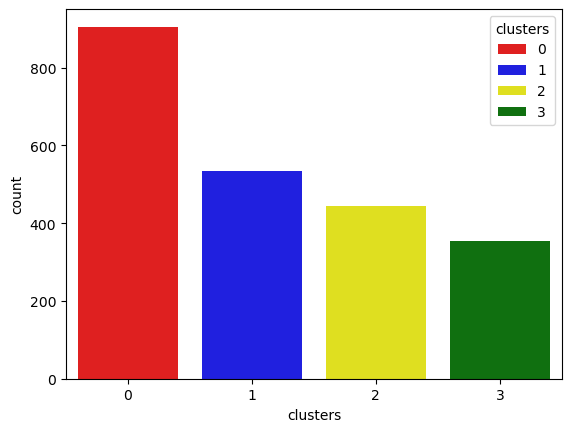

In [93]:
pal = ["red","blue","yellow","green"]

sns.countplot(x=df_cleaned["clusters"],palette=pal,hue=df_cleaned["clusters"])

<Axes: xlabel='total_spending', ylabel='Income'>

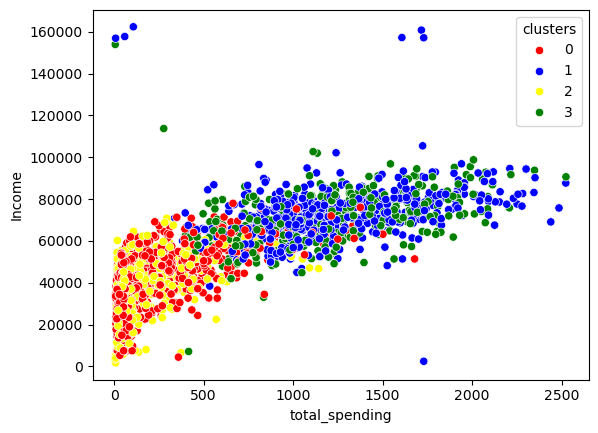

In [95]:
# since spending and income are highly correlated , so lets observe these 2 features in each cluster

sns.scatterplot(x = df_cleaned["total_spending"],y = df_cleaned["Income"],palette = pal,hue=df_cleaned["clusters"])

In [96]:
# cluster 0 : red -> low/moderate income , low/moderate spending
# cluster 1 : blue -> high income , high spending 
# cluster 2 : yellow -> low income , low spending
# cluster 3 : green -> moderate/high income , high spending  

In [99]:
X["cluster"] = labels_agg

In [100]:
# cluster summary 

cluster_summary = X.groupby("cluster").mean()
print(cluster_summary)

               Income    Recency  NumDealsPurchases  NumWebPurchases  \
cluster                                                                
0        39680.580110  48.914917           2.594475         3.153591   
1        72808.445693  49.202247           1.958801         5.687266   
2        36960.143018  48.319820           2.594595         2.713964   
3        70722.681303  50.504249           1.855524         5.790368   

         NumCatalogPurchases  NumStorePurchases  NumWebVisitsMonth  Complain  \
cluster                                                                        
0                   0.969061           4.143646           6.307182  0.011050   
1                   5.498127           8.659176           3.580524  0.005618   
2                   0.837838           3.623874           6.659910  0.011261   
3                   5.014164           8.430595           3.728045  0.005666   

         Response        Age  customer_tenure_days  total_spending  \
cluster         

In [101]:
# c0 : more children, price sensitive, poor response , partners, high web visit, web/cat/store purchases low
# c2 : more children, price sensitive,average response , alone, high web visit. web/cat/store purchases lowest

# c1 : fewer children, premium customers, slighty higher age, average response , partners, low web visit, store/cat/web purchases high
# c3 : fewer children, premium customers, slighty higher age, best response, alone,low web visit,store/cat/web purchases high

In [ ]:
# marketing strategies for each cluster

# co (family shoppers) -> discounts coupouns
# c1 -> loyalty programs
# c2 (single parents) -> sales / heavy discounts coupons
# c3 (high value singles) -> premium services / 1 to 1 services / personalized services